# Supplementary Figure 11. Sensitivity of converged TCN gain rates to alternative parameterizations of the TCN–growth relationship


In [1]:
%matplotlib inline
import os
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

os.environ.setdefault("SIM_RUN_MODE", "production")
%run ./simulation_core.ipynb

OUTPUT_ROOT, FIGURE_DIR, SOURCE_DIR = make_output_dirs("Supplementary_Figure_11_outputs")
PCN_CAPACITY_GRID=(np.array([100],dtype=int) if RUN_MODE=="quick" else np.arange(20,101,5,dtype=int))
PROFILES={"a":GrowthProfile("base",35,40),"b":GrowthProfile("stronger burden/protection",20,50),"c":GrowthProfile("further increased burden/protection",15,60)}
PCN_INC_F=TRANSITIONS.kappa_f_pcn-TRANSITIONS.kappa_f_on
PCN_INC_B=TRANSITIONS.kappa_b_pcn-TRANSITIONS.kappa_b_on
CONDITIONS={
 ("-PCN dynamics","transposition off"):(TRANSITIONS.kappa_f_off,TRANSITIONS.kappa_b_off),
 ("-PCN dynamics","transposition on"):(TRANSITIONS.kappa_f_on,TRANSITIONS.kappa_b_on),
 ("+PCN dynamics","transposition off"):(TRANSITIONS.kappa_f_off+PCN_INC_F,TRANSITIONS.kappa_b_off+PCN_INC_B),
 ("+PCN dynamics","transposition on"):(TRANSITIONS.kappa_f_pcn,TRANSITIONS.kappa_b_pcn),
}


In [2]:
rows=[]
for panel,profile in PROFILES.items():
    for max_pcn in PCN_CAPACITY_GRID:
        for (pcn_status,condition),(kf,kb) in CONDITIONS.items():
            config=make_configuration(int(max_pcn),condition=condition,kappa_f=kf,kappa_b=kb,setting_label=pcn_status)
            r=evaluate_configuration(int(max_pcn),config,growth_profile=profile)
            r.update({"panel":panel,"pcn_dynamics":pcn_status,"burden_scale":profile.burden_scale,"alpha":profile.protection_alpha})
            rows.append(r)
results=pd.DataFrame(rows)



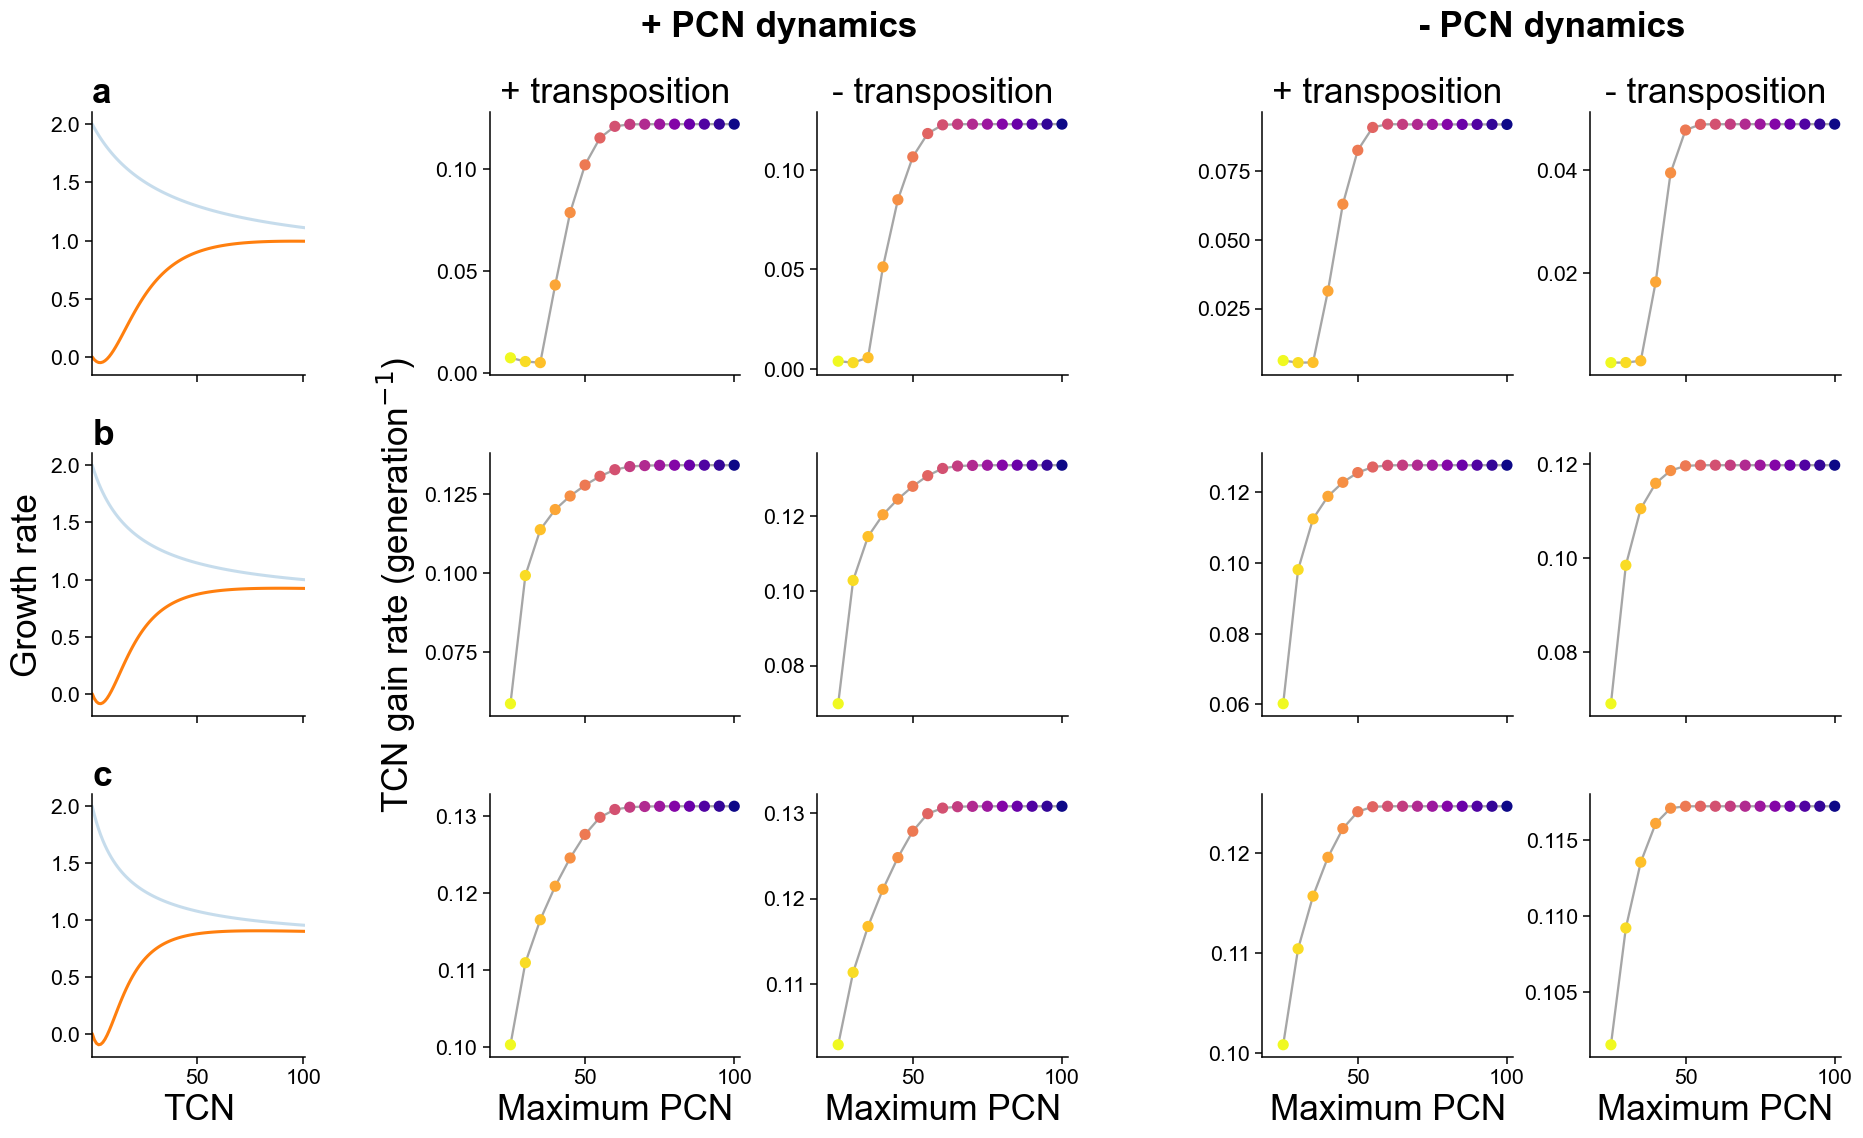

In [3]:
plt.rcParams.update(PLOT_STYLE)
LARGE_FONT_STYLE = {
    "font.size": 20, "axes.labelsize": 23, "axes.titlesize": 23,
    "xtick.labelsize": 14, "ytick.labelsize": 14, "legend.fontsize": 15,
    "axes.linewidth": 1.0, "xtick.major.width": 1.0, "ytick.major.width": 1.0,
    "xtick.major.size": 4.5, "ytick.major.size": 4.5,
}
plt.rcParams.update(LARGE_FONT_STYLE)
PANEL_FONT = 23

column_specs=[("+PCN dynamics","transposition on"),("+PCN dynamics","transposition off"),
              ("-PCN dynamics","transposition on"),("-PCN dynamics","transposition off")]
fig=plt.figure(figsize=(17.0,10.6))
gs=fig.add_gridspec(3,7,width_ratios=[0.85,0.12,1,1,0.16,1,1],left=0.055,right=0.99,
                    bottom=0.075,top=0.885,wspace=0.42,hspace=0.30)
rate_cols=(2,3,5,6)
group_axes={"+":[],"-":[]}
for r,(panel,profile) in enumerate(PROFILES.items()):
    ax=fig.add_subplot(gs[r,0]); x=total_tcn_states(100)
    ax.plot(x,growth_rates(100,selected=False,growth_profile=profile),alpha=0.25,lw=2)
    ax.plot(x,growth_rates(100,selected=True,growth_profile=profile),lw=2)
    ax.set_title(panel,loc="left",fontweight="bold",fontsize=PANEL_FONT); ax.set_xlim(1,101)
    if r==2: ax.set_xlabel("TCN")
    else: ax.tick_params(axis="x",labelbottom=False)
    if r==1: ax.set_ylabel("Growth rate")
    for c,(pcn_status,condition) in enumerate(column_specs):
        a=fig.add_subplot(gs[r,rate_cols[c]])
        d=results[(results.panel==panel)&(results.pcn_dynamics==pcn_status)&(results.condition==condition)&results.response_valid].sort_values("maximum_PCN")
        a.scatter(d.maximum_PCN,d.gain_rate,c=d.maximum_PCN,cmap="plasma_r",s=40,zorder=3)
        a.plot(d.maximum_PCN,d.gain_rate,color="0.65",lw=1.5)
        a.set_xlim(18,102)
        a.locator_params(axis="y",nbins=4)
        if r==2: a.set_xlabel("Maximum PCN")
        else: a.tick_params(axis="x",labelbottom=False)
        if c==0 and r==1: a.set_ylabel("TCN gain rate (generation$^{-1}$)")
        if r==0:
            a.set_title("+ transposition" if condition=="transposition on" else "- transposition")
            group_axes[pcn_status[0]].append(a)
for key,text in (("+","+ PCN dynamics"),("-","- PCN dynamics")):
    p0,p1=group_axes[key][0].get_position(),group_axes[key][1].get_position()
    fig.text((p0.x0+p1.x1)/2,0.958,text,ha="center",va="center",fontweight="bold",fontsize=23)
save_figure(fig,"Supplementary_Figure_11_growth_sensitivity",FIGURE_DIR); plt.show()

export_table(results,"Supplementary_Figure_11_source_data.csv",SOURCE_DIR)
export_table(core_metadata("Supplementary Figure 11"),"Supplementary_Figure_11_run_metadata.csv",SOURCE_DIR)
